# **How close are we to the Net Zero? How far are we?**

***Analysis of the current stage of energy transition, with data from Global Power Plant Database (World Resources Institute) and Ember***


 After the Paris agreement, most many contries aim to achieve net-zero by 2050, a quarter of a century from now, but as the demand grows and with the rise of middle east conflictthat led to the closure of the Strait of Hormuz, it became harder to reach net-zero before that target year. This project will analyse the current or most up-to-date status of the type of energy produced. The goal here is to help the audience understand the current stage of the energy transition and how far we are from achieving net zero, which ideally should lead to actions that contribute to a more sustainable society. 

The questions below are made as main points and to draw the scope of this project. The data used will be extracted from the Global Power Plant Database (World Resources Institute), with Ember's yearly electricity data (2000–2025) used at the end to show what has changed since 2017. 

 This analysis aims to answer the questions below and help readers understand the current stage of global energy, supporting informed decision-making.

- How much are we relying on fossil fuels compared to renewables? 
- Why just renewable energy not enough? 
- Which type of power plant produces the most electricity/energy? 
- Which countries rely most on renewables? Why is that? 



In [1]:
import zipfile
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import requests
import seaborn as sns

plt.style.use("seaborn-v0_8")
sns.set_palette("Set2")

DATA_DIR = Path("data")
FIG_DIR = Path("figures/energy_transition")
DATA_DIR.mkdir(exist_ok=True)
FIG_DIR.mkdir(parents=True, exist_ok=True)


def save_fig(name):
    """Save the current figure as a PNG so the README can show it."""
    plt.savefig(FIG_DIR / f"{name}.png", dpi=150, bbox_inches="tight")


/opt/anaconda3/lib/python3.12/site-packages/pandas/core/computation/expressions.py:23: UserWarning: Pandas requires version '2.10.2' or newer of 'numexpr' (version '2.8.7' currently installed).
  from pandas.core.computation.check import NUMEXPR_INSTALLED
/opt/anaconda3/lib/python3.12/site-packages/pandas/core/arrays/masked.py:56: UserWarning: Pandas requires version '1.4.2' or newer of 'bottleneck' (version '1.3.7' currently installed).
  from pandas.core import (


In [2]:
## Global Power Plant Database v1.3.0 (World Resources Institute)
# The old datasets.wri.org download link now returns 403, so this uses WRI's own S3 copy of the same file.
# It is saved to data/ on the first run, so later runs don't need the internet.
GPPD_URL = "https://wri-dataportal-prod.s3.amazonaws.com/manual/global_power_plant_database_v_1_3.zip"
GPPD_ZIP = DATA_DIR / "global_power_plant_database_v_1_3.zip"

if not GPPD_ZIP.exists():
    r = requests.get(GPPD_URL, timeout=120)
    r.raise_for_status()
    GPPD_ZIP.write_bytes(r.content)

with zipfile.ZipFile(GPPD_ZIP) as z:
    df = pd.read_csv(z.open("global_power_plant_database.csv"), low_memory=False)
df.head()


,country,country_long,name,gppd_idnr,capacity_mw,latitude,longitude,primary_fuel,other_fuel1,other_fuel2,...,estimated_generation_gwh_2013,estimated_generation_gwh_2014,estimated_generation_gwh_2015,estimated_generation_gwh_2016,estimated_generation_gwh_2017,estimated_generation_note_2013,estimated_generation_note_2014,estimated_generation_note_2015,estimated_generation_note_2016,estimated_generation_note_2017
0,AFG,Afghanistan,Kajaki Hydroelectric Power Plant Afghanistan,GEODB0040538,33.0,32.322,65.1190,Hydro,NaN,NaN,...,123.77,162.90,97.39,137.76,119.50,HYDRO-V1,HYDRO-V1,HYDRO-V1,HYDRO-V1,HYDRO-V1
1,AFG,Afghanistan,Kandahar DOG,WKS0070144,10.0,31.670,65.7950,Solar,NaN,NaN,...,18.43,17.48,18.25,17.70,18.29,SOLAR-V1-NO-AGE,SOLAR-V1-NO-AGE,SOLAR-V1-NO-AGE,SOLAR-V1-NO-AGE,SOLAR-V1-NO-AGE
2,AFG,Afghanistan,Kandahar JOL,WKS0071196,10.0,31.623,65.7920,Solar,NaN,NaN,...,18.64,17.58,19.10,17.62,18.72,SOLAR-V1-NO-AGE,SOLAR-V1-NO-AGE,SOLAR-V1-NO-AGE,SOLAR-V1-NO-AGE,SOLAR-V1-NO-AGE
3,AFG,Afghanistan,Mahipar Hydroelectric Power Plant Afghanistan,GEODB0040541,66.0,34.556,69.4787,Hydro,NaN,NaN,...,225.06,203.55,146.90,230.18,174.91,HYDRO-V1,HYDRO-V1,HYDRO-V1,HYDRO-V1,HYDRO-V1
4,AFG,Afghanistan,Naghlu Dam Hydroelectric Power Plant Afghanistan,GEODB0040534,100.0,34.641,69.7170,Hydro,NaN,NaN,...,406.16,357.22,270.99,395.38,350.80,HYDRO-V1,HYDRO-V1,HYDRO-V1,HYDRO-V1,HYDRO-V1


The most up-to-date available data is from the World Resources Institute (WRI), Global Power Plant Database is from 2017. This could be due to the difficulty and complexity of collecting, verifying, and standardising annual generation data for tens of thousands of power plants across more than 160 countries. This is still considered the most complete and best-verified global baseline possible with publicly available data; therefore, it will be used to best analyse the power plants.

To show what has changed since then, the last section adds **Ember's yearly electricity data**, which covers every country up to 2025.


## **Data Cleaning and Preparation**
Remove the unnecessary and missing values columns.  

In [3]:
# Only extract relevant columns
df = df[['country_long', 'name', 'capacity_mw',
        'primary_fuel','latitude', 'longitude',
        'estimated_generation_gwh_2013', 'estimated_generation_gwh_2014',
        'estimated_generation_gwh_2015', 'estimated_generation_gwh_2016',
        'estimated_generation_gwh_2017']].copy()

# Shorter name for the charts
df["country_long"] = df["country_long"].replace("United States of America", "USA")

# Fuel categories used in every section below.
# Cogeneration (combined heat and power) is mostly gas-fired and Storage only shifts power in time,
# so both go in "Other" rather than renewables.
fossil_fuels = ['Coal', 'Gas', 'Oil', 'Petcoke']
renewables = ['Hydro', 'Solar', 'Wind', 'Waste', 'Biomass', 'Wave and Tidal', 'Geothermal']
nuclear = ['Nuclear']


def fuel_category(fuel):
    if fuel in fossil_fuels:
        return "Fossil Fuels"
    elif fuel in renewables:
        return "Renewables"
    elif fuel in nuclear:
        return "Nuclear"
    else:
        return "Other"


df['Fuel Category'] = df['primary_fuel'].apply(fuel_category)
df.head()


,country_long,name,capacity_mw,primary_fuel,latitude,longitude,estimated_generation_gwh_2013,estimated_generation_gwh_2014,estimated_generation_gwh_2015,estimated_generation_gwh_2016,estimated_generation_gwh_2017,Fuel Category
0,Afghanistan,Kajaki Hydroelectric Power Plant Afghanistan,33.0,Hydro,32.322,65.1190,123.77,162.90,97.39,137.76,119.50,Renewables
1,Afghanistan,Kandahar DOG,10.0,Solar,31.670,65.7950,18.43,17.48,18.25,17.70,18.29,Renewables
2,Afghanistan,Kandahar JOL,10.0,Solar,31.623,65.7920,18.64,17.58,19.10,17.62,18.72,Renewables
3,Afghanistan,Mahipar Hydroelectric Power Plant Afghanistan,66.0,Hydro,34.556,69.4787,225.06,203.55,146.90,230.18,174.91,Renewables
4,Afghanistan,Naghlu Dam Hydroelectric Power Plant Afghanistan,100.0,Hydro,34.641,69.7170,406.16,357.22,270.99,395.38,350.80,Renewables


## **Power Plant Map**
Let visualise quickly by looking at the world map below, the red are power plants using fossil fuels ('Coal', 'Gas', 'Oil'), whereas the blues representing renewables energy such as Hydro, solar and wind power, the yellow representing others that are not or can't be classified in these two categories such as Nuclear power plants. 

By visualising like this, we can immediately summarise that the number of renewable power plants is no less than the fossil fuel power plants, while there are a relatively small number of Nuclear power plants. The numeric comparison of these energy sources is presented in the next section. 

**Note**: The map is drawn as a static image so that it shows on GitHub.

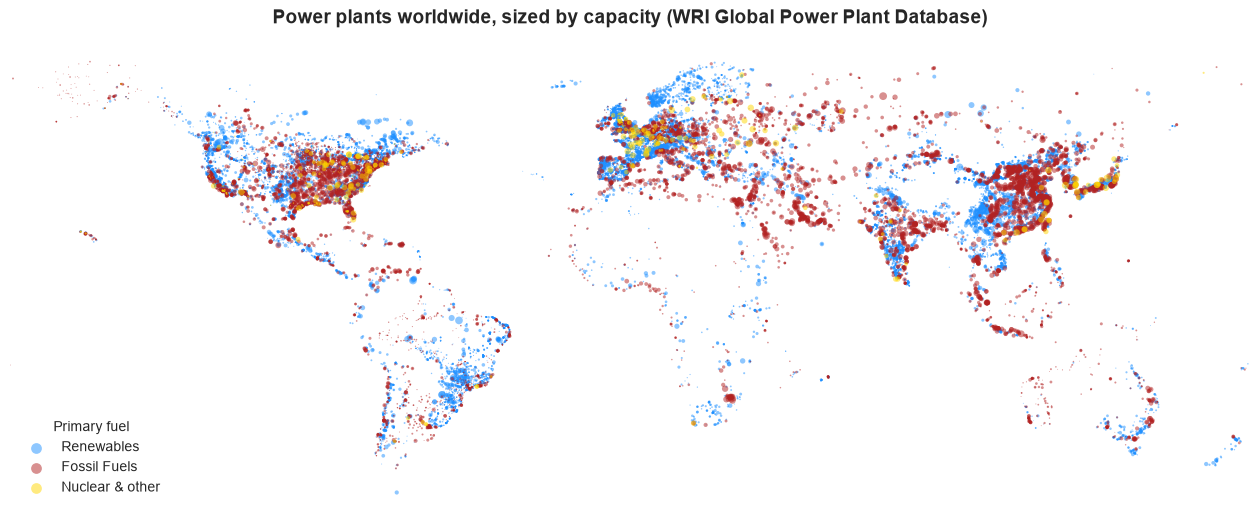

In [4]:
# Plot each plant at its longitude and latitude, sized by capacity.
# A static chart shows on GitHub, unlike an interactive folium map.
map_colors = {"Renewables": "dodgerblue", "Fossil Fuels": "firebrick", "Nuclear & other": "gold"}

fig, ax = plt.subplots(figsize=(16, 8))
for category, color in map_colors.items():
    plants = df[df["Fuel Category"].replace({"Nuclear": "Nuclear & other", "Other": "Nuclear & other"}) == category]
    ax.scatter(plants["longitude"], plants["latitude"], s=np.sqrt(plants["capacity_mw"]) / 3,
               color=color, alpha=0.5, linewidths=0, label=category)
ax.set_xlim(-180, 180)
ax.set_ylim(-58, 80)
ax.set_aspect("equal")
ax.set_axis_off()
legend = ax.legend(loc="lower left", title="Primary fuel")
for handle in legend.legend_handles:
    handle.set_sizes([60])  # same marker size for every entry
ax.set_title("Power plants worldwide, sized by capacity (WRI Global Power Plant Database)", fontsize=14, fontweight="bold")
save_fig("01_power_plant_map")
plt.show()


## **Number of Power Plants** : *How many are there?*
To understand the current status: the number of power plants that are renewables versus fossil fuels.

In [5]:
# Count number of power plants by fuel type
fuel_counts = df["primary_fuel"].value_counts().reset_index()
fuel_counts.columns = ["Fuel Type", "Number of Plants"]

# Display as a styled table
fuel_counts.style.format({"Number of Plants": "{:,}"}).hide(axis="index").set_caption("Number of Power Plants by Fuel Type").set_table_styles([
    {"selector": "caption", "props": [("font-size", "14px"), ("font-weight", "bold"), ("color", "black"), ("text-align", "center")]}
])

Fuel Type,Number of Plants
Solar,"10,665"
Hydro,"7,156"
Wind,"5,344"
Gas,"3,998"
Coal,"2,330"
Oil,"2,320"
Biomass,"1,430"
Waste,"1,068"
Nuclear,195
Geothermal,189


In [6]:
# Count plants in each fuel category (categories are defined in the data preparation step)
category_counts = df['Fuel Category'].value_counts().reset_index()
category_counts.columns = ["Category", "Number of Plants"]

# Display as a styled table
category_counts.style.hide(axis="index").format({"Number of Plants": "{:,}"}).set_caption("Number of Power Plants by Category").set_table_styles([
    {"selector": "caption", "props": [("font-size", "14px"), ("font-weight", "bold"), ("color", "black"), ("text-align", "center")]}
])


Category,Number of Plants
Renewables,"25,862"
Fossil Fuels,"8,660"
Other,219
Nuclear,195


The 'Coal', 'Gas', 'Oil', and 'Petcoke' (Petroleum coke) are classified as fossil fuels, while'Hydro', 'Solar', 'Wind', 'Waste', 'Biomass', 'Wave and Tidal', and 'Geothermal' are classified as renewables. 

**Comment**: There are much more number of renewable power plants comparing to the fossil fules, this is because renewable is classified for a wider range whereas fossil fuels are limited to only Gas, Oil and Coal and also Petroleum coke for this project. In addition, the fabrication and installation of wind and solar power are much easier and require a much shorter time than the construction of a refinery or distillation site. 

As shown on the table above, there are 25,862 renewables plants compared to only 8,660 fossil fuel power plants. 

Despite the number, have you ever wondered how much really renewable produce? Compared to fossil fuels? What is the percentage worldwide? 

**Note**: Nuclear, Storage and Cogeneration are considered neither renewables nor fossil fuels. Cogeneration (combined heat and power) is a technology rather than a fuel, and most of these plants burn gas. Petroleum coke is considered a fossil fuel because of its origin as a byproduct of crude oil

## **Energy Generation** : *How much are we relying on the fossil fuels? How much of the total energy generated is from fossil fuels?*

This section will prove that despite the increasing number of renewable plants, most of the energy we use today is produced by fossil fuels.

This will present how much has to be done in order to achieve or get closer to net-zero. 

In [7]:
#Calculate total estimated energy generated in 2017
total_energy = df['estimated_generation_gwh_2017'].sum()

# Calculate energy generated by fossil fuels
fossil_energy = df[df['primary_fuel'].isin(fossil_fuels)]['estimated_generation_gwh_2017'].sum()

# Calculate energy generated by renewables
renewable_energy = df[df['primary_fuel'].isin(renewables)]['estimated_generation_gwh_2017'].sum()


# Calculate percentages
fossil_pct = fossil_energy / total_energy * 100
renewable_pct = renewable_energy / total_energy * 100
other_pct = 100 - (fossil_pct + renewable_pct) 
generation_renewable_pct = renewable_pct  # kept for the Ember comparison at the end

print(f"Fossil Fuels: {fossil_pct:.1f}%")
print(f"Renewable: {renewable_pct:.1f}%")
print(f"Others: {other_pct:.1f}%")

summary = pd.DataFrame({
    "Category": ["Fossil Fuels", "Renewable"],
    "Energy Generated (GWh)": [fossil_energy, renewable_energy],
    "Percentage of Total (%)": [fossil_pct, renewable_pct]
})


summary.style.hide(axis="index").format({
    "Energy Generated (GWh)": "{:,.0f}",
    "Percentage of Total (%)": "{:.1f}%"
}).set_caption("Global Energy Generation in 2017 (Estimated)").set_table_styles([
        {
            "selector": "caption",
            "props": [("font-size", "14px"), ("font-weight", "bold"),("color", "black"),
            ("text-align", "center")]
        }
    ])


Fossil Fuels: 68.1%
Renewable: 19.6%
Others: 12.3%


Category,Energy Generated (GWh),Percentage of Total (%)
Fossil Fuels,"16,176,169",68.1%
Renewable,"4,646,392",19.6%


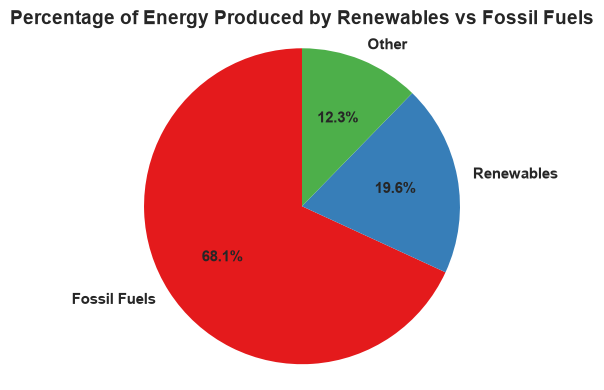

In [8]:
# Combine counts for pie chart
labels = ['Fossil Fuels', 'Renewables', 'Other']
sizes = [fossil_pct, renewable_pct, other_pct]
# Use the already defined 'colors' variable
colors = sns.color_palette("Set1", len(sizes)) # Colour from seaborn(plasma, magma, or cividis)

plt.figure(figsize=(6,4))
plt.pie(sizes, labels=labels, autopct='%1.1f%%', colors=colors, startangle=90, textprops={'fontsize': 11, 'fontweight': 'bold'})
plt.title('Percentage of Energy Produced by Renewables vs Fossil Fuels', fontsize=14, fontweight='bold')
plt.axis('equal')
plt.tight_layout()
save_fig("02_generation_share_2017")
plt.show()


More than half of the energy generated worldwide is from fossil fuels, and only 19.6% is from renewables. This suggests that a lot of work has to be done; for example, nuclear power might be necessary to meet the energy demand. 

### **Installed Capacity**
Installed capacity is the maximum potential electrical power output that a generating unit or an entire power plant can produce under optimal, sustained conditions. This will show the case that if we push the renewable sources to the limit at the current stage, what percentage will the percentage be like. This result will not be that helpful because solar and wind, or even hydro, are relying on uncontrollable factors. Overall, this will show how much the fossil fuel power plant can produce compared to the renewables, excluding the external factors. 

In [9]:
# Total installed capacity
total_energy = df['capacity_mw'].sum()

# Calculate energy generated by fossil fuels
fossil_energy = df[df['primary_fuel'].isin(fossil_fuels)]['capacity_mw'].sum()

# Calculate energy generated by renewables
renewable_energy = df[df['primary_fuel'].isin(renewables)]['capacity_mw'].sum()


# Calculate percentages
fossil_pct = fossil_energy / total_energy * 100
renewable_pct = renewable_energy / total_energy * 100
other_pct = 100 - (fossil_pct + renewable_pct) 

print(f"Fossil Fuels: {fossil_pct:.1f}%")
print(f"Renewable: {renewable_pct:.1f}%")
print(f"Others: {other_pct:.1f}%")

summary = pd.DataFrame({
    "Category": ["Fossil Fuels", "Renewable"],
    "Installed Capacity (mW)": [fossil_energy, renewable_energy],
    "Percentage of Total (%)": [fossil_pct, renewable_pct]
})


summary.style.hide(axis="index").format({
    "Installed Capacity (mW)": "{:,.0f}",
    "Percentage of Total (%)": "{:.1f}%"
}).set_caption("Installed Capacity (mW)").set_table_styles([
        {
            "selector": "caption",
            "props": [("font-size", "14px"), ("font-weight", "bold"),("color", "black"),
            ("text-align", "center")]
        }
    ])


Fossil Fuels: 65.2%
Renewable: 27.5%
Others: 7.3%


Category,Installed Capacity (mW),Percentage of Total (%)
Fossil Fuels,"3,722,895",65.2%
Renewable,"1,566,796",27.5%


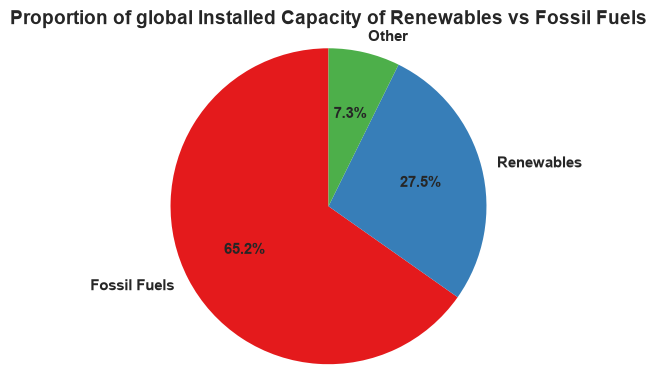

In [10]:
# Combine counts for pie chart
labels = ['Fossil Fuels', 'Renewables', 'Other']
sizes = [fossil_pct, renewable_pct, other_pct]
# Use the already defined 'colors' variable

plt.figure(figsize=(6,4))
plt.pie(sizes, labels=labels, autopct='%1.1f%%', colors=colors, startangle=90, textprops={'fontsize': 11, 'fontweight': 'bold'})
plt.title('Proportion of global Installed Capacity of Renewables vs Fossil Fuels', fontsize=14, fontweight='bold')
plt.axis('equal')
plt.tight_layout()
save_fig("03_capacity_share")
plt.show()

The percentage looks better than the amount of energy produced, but still shows that we are very far from achieving net-zero. 

## **Which type of power plant produce the most energy?**  
Have you ever wonder what type of power are we relying on the most? This section will present the share of energy generated by specific type of power plants extended from the comparison between renewables and fossil fuels. This section will also answer the following questions:

- What type of power plant does the world rely on most?
- Why is it used the most?
- Where does most renewable energy come from?

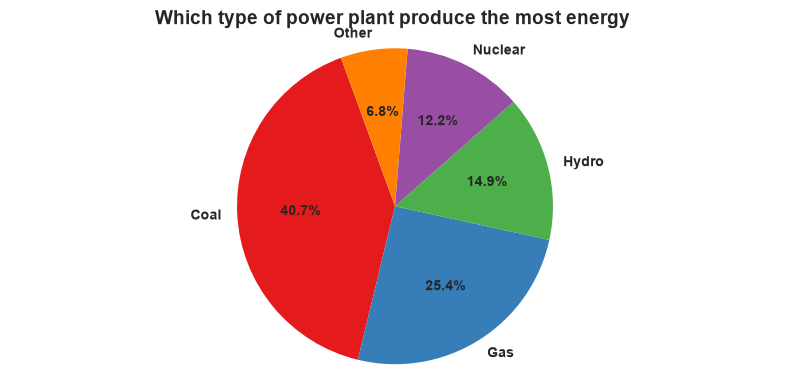

In [11]:
# Select the most recent year available
year = "estimated_generation_gwh_2017"

# Group by primary fuel and sum the energy generated
Plant_energy_estimate = df.groupby("primary_fuel")[year].sum().sort_values(ascending=False) 


# Calculate percentage share for each fuel type
total_energy = Plant_energy_estimate.sum()
percentages = Plant_energy_estimate / total_energy * 100

# Group those less than 10% into 'Other'
main_types = percentages[percentages >= 10]
other_sum = percentages[percentages < 10].sum()


# Prepare final data for pie chart
final_plot = main_types.copy()
if other_sum: 
    final_plot['Other'] = other_sum

final_plot 

colors = sns.color_palette("Set1", len(final_plot))

plt.figure(figsize=(8,4))
plt.pie(
    final_plot,
    labels=final_plot.index,
    autopct='%1.1f%%',
    startangle=110,
    colors=colors,
    textprops={'fontsize': 10, 'fontweight': 'bold'}
)
plt.title("Which type of power plant produce the most energy ", fontsize=14, fontweight='bold')
plt.axis('equal')
plt.tight_layout()
save_fig("04_generation_by_fuel_2017")
plt.show()

The results show that 40.7% of the energy generated are from coal, this is controversial to the net-zero target because coal is widely known as the single most environmentally damaging energy source, producing the most CO2 emissions of 0.790 kg CO2e/kWh, more than those produced from Oil and Gas (0.602 and 0.497 kg CO2e/kWh respectively). Interestingly, the amount of energy produced coming from oil is lower than 10%, less than those producing from hydro power energy. 

**Opinion:** What make Hydro power the most used renewables?, Why does Oil plants produce such a low share amount of energy comparing to the other sources? 

**Source:** https://questions-statements.parliament.uk/written-questions/detail/2015-11-26/17799

# **What countries can generate the most energy? How good is the UK doing comparing to the US?** 

We all know that China and USA are the leader in technology and energy capacity, the table below shows graphically their installed capacity comparing to the rest of the world. USA produce at least 3 times more than India (the country with the third installed capacity). 

But how renewables are these leaders? producing the most does not mean they are the most renewables due to the growing energy demand which is correlated with the population and emerging of technologies. 

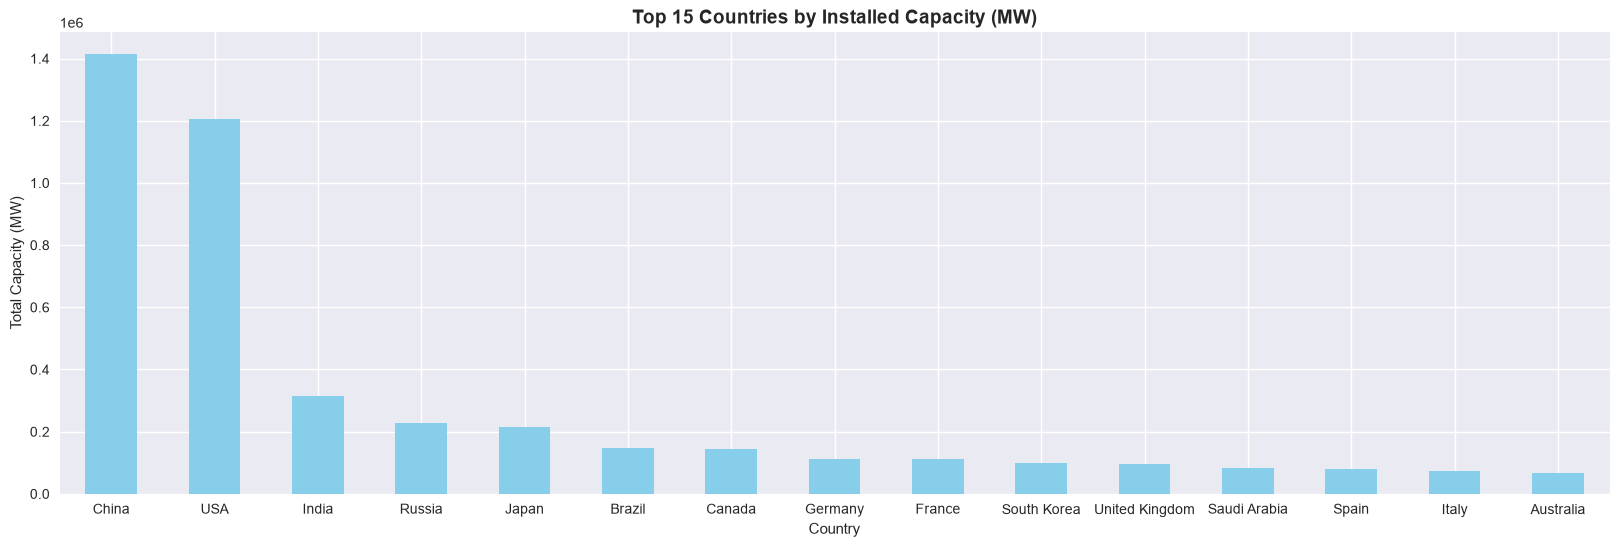

In [12]:
country_capacity = df.groupby("country_long")["capacity_mw"].sum().sort_values(ascending=False).head(15)

plt.figure(figsize=(20,6))
country_capacity.plot(kind="bar", color='skyblue')
plt.title("Top 15 Countries by Installed Capacity (MW)", fontsize=14, fontweight='bold')
plt.ylabel("Total Capacity (MW)")
plt.xlabel("Country")
plt.xticks(rotation=0)
save_fig("05_top15_capacity")
plt.show()


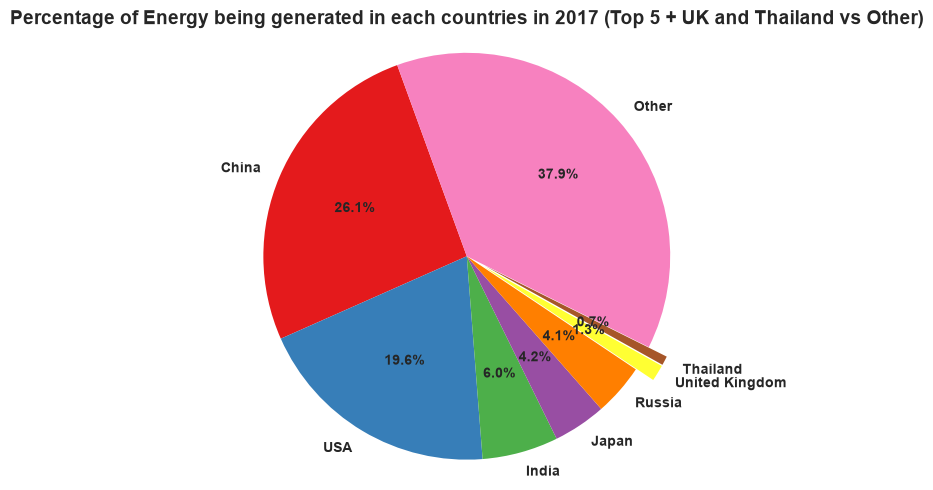

In [13]:
# Select the most recent year available
year = "estimated_generation_gwh_2017"

Generate_estimate = df.groupby("country_long")[year].sum().sort_values(ascending=False) 

top5_energy = Generate_estimate.head(5)


uk_energy = Generate_estimate.loc['United Kingdom']
Thailand_energy = Generate_estimate.loc['Thailand']

selected = pd.concat([top5_energy, pd.Series({"United Kingdom": uk_energy}), pd.Series({"Thailand": Thailand_energy})])

other = Generate_estimate.drop(selected.index).sum()  # Drop top 5 and UK, Thailand, sum the rest


# Plot as pie chart
final_plot = pd.concat([selected, pd.Series({"Other": other})])
explode = [0.1 if c in ("United Kingdom", "Thailand") else 0 for c in final_plot.index]  # explode UK & Thailand
colors = sns.color_palette("Set1", len(final_plot)) # Colour from seaborn(plasma, magma, or cividis)

plt.figure(figsize=(8,5))
plt.pie(
    final_plot,
    labels=final_plot.index,
    autopct='%1.1f%%',
    startangle=110,
    colors = colors,
    explode = explode,
    textprops={'fontsize': 10, 'fontweight': 'bold'}
)
plt.title("Percentage of Energy being generated in each countries in 2017 (Top 5 + UK and Thailand vs Other)", fontsize=14, fontweight='bold')
plt.axis('equal')  # Equal aspect ratio ensures that pie is drawn as a circle.
plt.tight_layout()
save_fig("06_generation_by_country_2017")
plt.show()

China and USA combined use almost half of the world energy generated. 

## **Which countries rely heavily on non-renewable energy?/Which one has to do more work to achieve net-zero?** 

The figure below illustrates the share of installed capacity of the top 10 countries with the highest installed capacity plus the UK, whether they are more relying on fossil fuels, renewables or nuclear. The result shows that both China and USA are relying heavily on fossil fuels, showing that they will need alot of effort and investment and time to achieve the net-zero. 

The result also shows that the United Kingdom is doing better than most countries as lower than 50% of the installed capacity are fossil fuels. 
With the current effort of the government and new energy projects such as Hinky Point C, evolve of small modular nuclear reactor and heavy research from universities, the UK is in the right track of achieving net-zero while comparing to the world leader like USA and China. 

*UK is doing very good! We are on the right track >>>*  

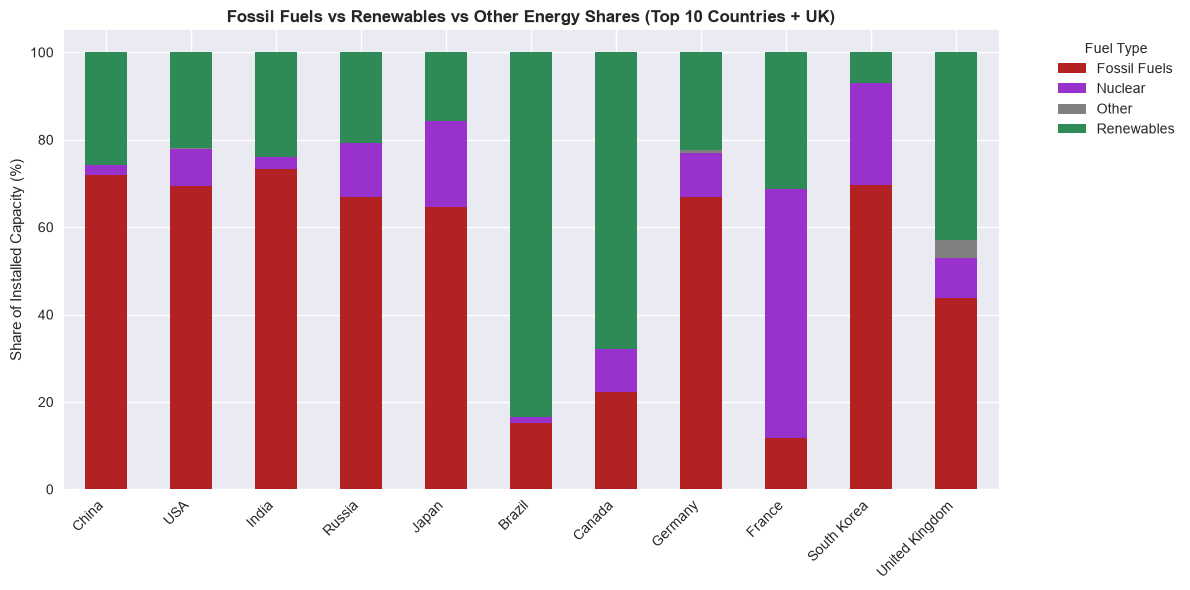

In [14]:
country_fuel = df.groupby(["country_long", "Fuel Category"])["capacity_mw"].sum().unstack(fill_value=0)

# --- Top 10 countries by total capacity, plus the UK ---
top_countries = country_fuel.sum(axis=1).sort_values(ascending=False).head(10).index.tolist()
if "United Kingdom" not in top_countries:
    top_countries.append("United Kingdom")
top_data = country_fuel.loc[top_countries]

# --- Normalize to percentages ---
top_data_pct = top_data.div(top_data.sum(axis=1), axis=0) * 100

# --- Plot stacked bar ---
category_colors = {"Fossil Fuels": "firebrick", "Nuclear": "darkorchid", "Other": "grey", "Renewables": "seagreen"}
top_data_pct.plot(kind="bar", stacked=True, figsize=(12,6),
                    color=[category_colors[c] for c in top_data_pct.columns])

plt.ylabel("Share of Installed Capacity (%)")
plt.xlabel(None)
plt.title("Fossil Fuels vs Renewables vs Other Energy Shares (Top 10 Countries + UK)", fontsize=12, fontweight='bold')
plt.xticks(rotation=45, ha="right")
plt.legend(title="Fuel Type", bbox_to_anchor=(1.05, 1))
plt.tight_layout()
save_fig("07_capacity_mix_top10_uk")
plt.show()


In [15]:
# List of countries to compare
countries = ['Brazil', 'United Kingdom', 'USA']

# Prepare a results dictionary
results = {}

for country in countries:
    country_df = df[df['country_long'] == country]
    total_energy = country_df['capacity_mw'].sum()
    renewable_energy = country_df[country_df['Fuel Category'] == 'Renewables']['capacity_mw'].sum()
    pct_renewable = (renewable_energy / total_energy * 100) if total_energy > 0 else 0
    results[country] = pct_renewable

# Display results
for country, pct in results.items():
    print(f"{country}: {pct:.1f}% renewable share of installed capacity")

Brazil: 83.4% renewable share of installed capacity
United Kingdom: 43.0% renewable share of installed capacity
USA: 21.8% renewable share of installed capacity


### **Interesting result is that, 83.4% of Brazil's installed capacity is renewables, more than any other countries. Why is that?? What make Brazil so good?**


However, Brazil is not close to achieving overall net-zero emissions. Unlike many countries where the energy sector is the biggest polluter, Brazil's emissions are dominated by Land Use, Land-Use Change, and Forestry (LULUCF). The primary driver of these emissions is deforestation, particularly in the Amazon, followed by the agriculture sector.

# **What has changed since 2017?**

The power plant database stops in 2017, so this section uses **Ember's yearly electricity data** (2000–2025) to see how the world and the UK have moved since then.
Ember reports each country's share of electricity generation by fuel, from national statistics.


In [16]:
# Ember yearly electricity data. The full file is about 50 MB, so only the generation shares (%)
# are kept and saved to data/ on the first run.
EMBER_URL = "https://storage.googleapis.com/emb-prod-bkt-publicdata/public-downloads/yearly_full_release_long_format.csv"
EMBER_FILE = DATA_DIR / "ember_generation_share.csv"

if not EMBER_FILE.exists():
    ember_raw = pd.read_csv(EMBER_URL)
    keep = (ember_raw["Category"] == "Electricity generation") & (ember_raw["Unit"] == "%")
    ember_raw.loc[keep, ["Area", "Year", "Variable", "Value"]].to_csv(EMBER_FILE, index=False)

ember = pd.read_csv(EMBER_FILE).pivot_table(index=["Area", "Year"], columns="Variable", values="Value")
print(f"Ember data: {ember.index.get_level_values('Year').min()}-{ember.index.get_level_values('Year').max()}, "
      f"{ember.index.get_level_values('Area').nunique()} countries and regions")

# How do the two sources compare in 2017? WRI only counts plants in its database and estimates their output.
print(f"World renewables share of generation in 2017: WRI {generation_renewable_pct:.1f}%, "
      f"Ember {ember.loc[('World', 2017), 'Renewables']:.1f}%")

areas = {"World": "World", "United Kingdom": "UK", "United States of America": "USA",
         "China": "China", "Brazil": "Brazil", "Thailand": "Thailand"}
cols = ["Fossil", "Coal", "Gas", "Wind and Solar", "Renewables", "Nuclear"]
change = pd.concat({
    year: ember.xs(year, level="Year").loc[list(areas), cols].rename(index=areas)
    for year in [2017, 2025]
}, axis=1).swaplevel(axis=1)[cols]
print("\nShare of electricity generation (%), 2017 vs 2025:")
print(change.round(1).fillna(0).to_string())


Ember data: 2000-2025, 227 countries and regions
World renewables share of generation in 2017: WRI 19.6%, Ember 24.5%

Share of electricity generation (%), 2017 vs 2025:
Variable Fossil        Coal         Gas       Wind and Solar       Renewables       Nuclear      
           2017  2025  2017  2025  2017  2025           2017  2025       2017  2025    2017  2025
Area                                                                                             
World      65.3  57.4  38.0  33.1  23.5  21.7            6.2  17.3       24.5  33.8    10.2   8.9
UK         50.0  35.6   6.7   0.1  40.4  31.1           18.1  36.0       29.2  52.0    20.8  12.4
USA        62.7  57.0  29.8  16.3  32.0  40.0            8.2  18.9       17.5  25.6    19.9  17.4
China      71.0  58.4  67.1  54.6   3.1   3.0            6.4  21.8       25.2  37.0     3.8   4.6
Brazil     18.1  11.3   3.9   2.3  11.1   7.3            7.3  27.5       79.2  86.6     2.7   2.1
Thailand   88.9  83.4  20.2  17.8  68.5  65.5 

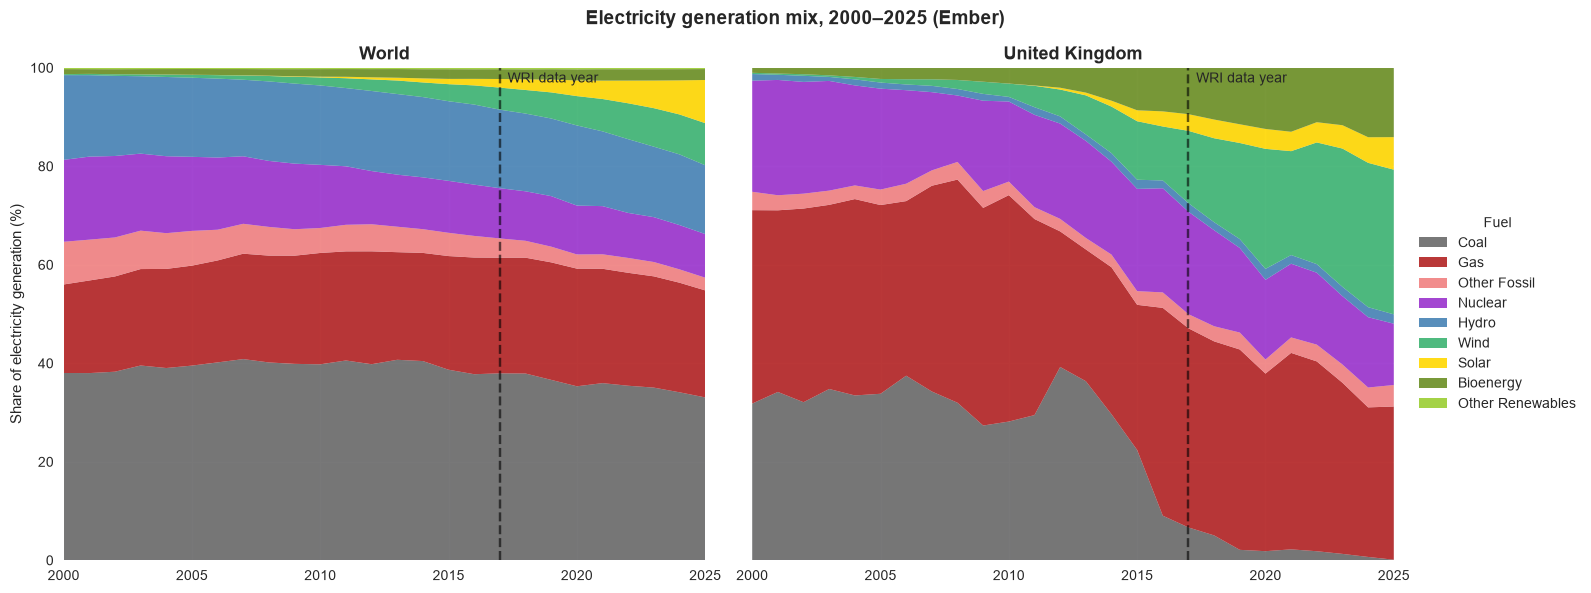

In [17]:
# Generation mix over time: World vs UK
fuels = {
    "Coal": "dimgrey", "Gas": "firebrick", "Other Fossil": "lightcoral", "Nuclear": "darkorchid",
    "Hydro": "steelblue", "Wind": "mediumseagreen", "Solar": "gold", "Bioenergy": "olivedrab",
    "Other Renewables": "yellowgreen",
}
fig, axes = plt.subplots(1, 2, figsize=(16, 6), sharey=True)
for ax, (area, label) in zip(axes, [("World", "World"), ("United Kingdom", "United Kingdom")]):
    mix = ember.loc[area, list(fuels)]
    ax.stackplot(mix.index, mix.T, labels=fuels.keys(), colors=fuels.values(), alpha=0.9)
    ax.axvline(2017, color="black", linestyle="--", alpha=0.6)
    ax.text(2017.3, 97, "WRI data year", fontsize=10)
    ax.set_title(label, fontsize=13, fontweight="bold")
    ax.set_xlim(mix.index.min(), mix.index.max())
    ax.set_ylim(0, 100)
axes[0].set_ylabel("Share of electricity generation (%)")
axes[1].legend(loc="center left", bbox_to_anchor=(1.02, 0.5), title="Fuel")
fig.suptitle("Electricity generation mix, 2000–2025 (Ember)", fontsize=14, fontweight="bold")
plt.tight_layout()
save_fig("08_generation_mix_world_uk")
plt.show()


### **What the Ember data shows**

**World: moving, but slowly.**
- Fossil fuels fell from 65.3% of electricity in 2017 to 57.4% in 2025, but **coal is still the largest single source at 33.1%** (38.0% in 2017).
- Wind and solar almost tripled, from 6.2% to 17.3%, and all renewables rose from 24.5% to 33.8%.
- China cut coal from 67.1% to 54.6% and grew wind and solar from 6.4% to 21.8%. The USA cut coal from 29.8% to 16.3%, mostly by switching to gas (32.0% → 40.0%).

**UK: coal is gone, gas is what's left.**
- Coal went from 6.7% to 0.1%. The last coal plant, Ratcliffe-on-Soar, closed in September 2024.
- Wind and solar doubled from 18.1% to 36.0%, and renewables now make **52.0%** of UK electricity.
- Fossil fuels fell from 50.0% to 35.6%, and **almost all of that is gas (31.1%)**. Nuclear also fell, from 20.8% to 12.4%, as old reactors retire.

This is why the UK power price still follows gas: gas plants are the only flexible fossil plants left, and they fill the gap whenever wind and solar fall short, so they set the price most of the time. The **UK Gas Power 2026** notebook tests this with half-hourly prices.

**Note on the two sources:** for 2017, WRI gives 19.6% renewables while Ember gives 24.5%. WRI only estimates output for the plants in its database, while Ember uses national statistics, so the WRI generation shares should be read as a rough picture rather than exact numbers.


- How much are we relying on the fossil fuels comparing to renewables? 
- Why just renewable energy is not enough? Energy demand 
- Which type of power plant produce is the most use? Coal 
- Which countries rely most on renewables? Why is that? Brazil 


**Reflection and suggestion for next step:** The US and China together are responsible for almost half of the world energy generation and installed capacity. However, both still relying most on the fossil fuels, suggesting how much work have to be done, for the world leaders. Their effort for energy transition can set an example for the rest of the world and affect how renewables the world is significantly. 


The UK is on the right track, though other assessment will be required to validate because carbon emissions is increasing from factors like transportation and industry.

**Update with 2025 data (Ember):** since 2017 the UK has closed its last coal plant and doubled wind and solar, so renewables now produce just over half of UK electricity. The world has moved more slowly: wind and solar have nearly tripled, but coal still produces a third of global electricity. The UK's remaining fossil power is almost entirely gas, which keeps the UK power price tied to the gas price.
